In [1]:
import torch
import lightning.pytorch as pl
from torch import nn
# from transformers import (
#     T5EncoderModel,
#     T5Tokenizer,
#     AutoTokenizer
# )
import numpy as np
import peft
from peft import LoraConfig, inject_adapter_in_model

from typing import Optional, Dict, Any
from torchmetrics import Accuracy

from mhcicleave.models import MLP, CNN

In [21]:
from torchmetrics import Accuracy, AUROC


In [ ]:

# ----------------------------------------------------------------------------
# Definimos una clase que hereda de pl.LightningModule y encapsula:
#  1) el modelo HF con LoRA
#  2) los pasos de entrenamiento/validación
#  3) la configuración del optimizador
# ----------------------------------------------------------------------------

class LoRATokenClassificationModule(pl.LightningModule):
    def __init__(
        self,
        checkpoint: str = "Rostlab/prot_t5_xl_uniref50",
        num_labels: int = 3,
        lr: float = 1e-4,
        use_lora: bool = True,
        freeze_base: bool = False,
        **kwargs
    ):
        """
        Args:
            checkpoint: nombre del checkpoint de HF, p.ej. un ProtT5
            num_labels: número de clases para la clasificación por residuo
            lr: learning rate
            use_lora: si True, inyecta adaptadores LoRA
            freeze_base: si True, congela la mayor parte de los pesos base
        """
        super().__init__()
        self.save_hyperparameters()  # Guarda hiperparámetros en el checkpoint

        self.num_labels = num_labels
        self.lr = lr

        # 1) Cargamos encoder + tokenizer
        #    (puedes adaptarlo para ESM, ankh, ProstT5, etc.)
        self.tokenizer = T5Tokenizer.from_pretrained(checkpoint, do_lower_case=False)
        self.encoder = T5EncoderModel.from_pretrained(checkpoint)

        # 2) Definimos cabecera de clasificación
        hidden_dim = self.encoder.config.hidden_size  # p.ej. 1024 para prot_t5_xl
        self.classifier = nn.Linear(hidden_dim, num_labels)

        # 3) Congelamos pesos base si deseamos
        if freeze_base:
            for param in self.encoder.parameters():
                param.requires_grad = False

        # 4) Inyectamos LoRA si se desea
        if use_lora:
            peft_config = LoraConfig(
                r=4,
                lora_alpha=1,
                bias="none",
                target_modules=["q", "k", "v", "o"],  # para T5
            )
            # Inyecta adaptadores en el encoder
            self.encoder = inject_adapter_in_model(peft_config, self.encoder)
            # Ojo: no olvides entrenar la classifier
            for p_name, param in self.classifier.named_parameters():
                param.requires_grad = True

        # 5) Métrica
        #    Para token classification definimos la exactitud en GPU
        self.acc = Accuracy(
            task="multiclass",  # PyTorch Lightning >=2.0
            num_classes=num_labels,
            multidim_average="global",  # todos los tokens
        )

    def forward(self, input_ids, attention_mask=None, labels=None):
        """
        input_ids: [batch_size, seq_len]
        labels:    [batch_size, seq_len], opcional
        """
        outputs = self.encoder(input_ids, attention_mask=attention_mask)
        hidden_states = outputs.last_hidden_state  # [B, seq_len, hidden_dim]
        logits = self.classifier(hidden_states)    # [B, seq_len, num_labels]

        return logits

    def training_step(self, batch, batch_idx):
        # batch["input_ids"]:  [B, seq_len]
        # batch["attention_mask"]: [B, seq_len]
        # batch["labels"]: [B, seq_len], con -100 en posiciones que se ignoran
        input_ids = batch["input_ids"]
        attention_mask = batch["attention_mask"]
        labels = batch["labels"]

        logits = self(input_ids, attention_mask=attention_mask)
        loss, acc = self._compute_loss_and_acc(logits, labels, attention_mask)

        self.log("train_loss", loss, on_step=True, on_epoch=True)
        self.log("train_acc", acc,  on_step=True, on_epoch=True)
        return loss
    
    def validation_step(self, batch, batch_idx):
        input_ids = batch["input_ids"]
        attention_mask = batch["attention_mask"]
        labels = batch["labels"]

        logits = self(input_ids, attention_mask=attention_mask)
        loss, acc = self._compute_loss_and_acc(logits, labels, attention_mask)

        self.log("val_loss", loss, prog_bar=True)
        self.log("val_acc", acc,  prog_bar=True)

        return loss

    def _compute_loss_and_acc(self, logits, labels, attention_mask):
        """
        Calcula la CrossEntropy ignorando indices = -100,
        y computa la exactitud con la métrica torchmetrics.
        """
        # logits shape: [B, seq_len, num_labels]
        # labels shape: [B, seq_len] (posiciones -100 se ignoran)
        b, seq_len, _ = logits.shape

        # Reorganizamos en [B*seq_len, num_labels]
        logits_2d = logits.view(-1, self.num_labels)
        labels_1d = labels.view(-1)

        # Ignoramos posiciones -100
        loss_fct = nn.CrossEntropyLoss(ignore_index=-100)
        loss = loss_fct(logits_2d, labels_1d)

        # Para exactitud, primero filtramos labels != -100
        valid_idx = (labels_1d != -100)
        valid_labels = labels_1d[valid_idx]
        valid_logits = logits_2d[valid_idx]

        preds = valid_logits.argmax(dim=-1)
        # Calculamos exactitud con torchmetrics
        # (llamamos self.acc.update(...) o self.acc(preds, valid_labels) segun la version)
        acc = self.acc(preds, valid_labels)

        return loss, acc

    def configure_optimizers(self):
        """
        Define el optimizador y el LR scheduler si deseas.
        Aquí es un ejemplo simple con AdamW.
        """
        optimizer = torch.optim.AdamW(self.parameters(), lr=self.lr)
        # Podríamos devolver un diccionario con 'lr_scheduler' si quisiéramos.
        return optimizer



In [1]:
# mlp_lightning.py (por ejemplo)
import pickle
import torch
import lightning.pytorch as pl
import numpy as np
from torch import nn
from torch.optim import Adam
from torch.optim.lr_scheduler import StepLR
from sklearn.metrics import roc_auc_score
from mhcicleave.models import MLP  # <-- igual que en tu repo
from datasets import load_dataset, load_from_disk, Dataset
from torch.utils.data import DataLoader
from torchmetrics import AUROC, MatthewsCorrCoef, Accuracy,ConfusionMatrix, ROC
from torchmetrics import MetricCollection,MetricTracker


class LightningModel(pl.LightningModule):
    def __init__(self, model, lr=0.001, step_size=3, gamma=0.1):
        """
        Un LightningModule genérico para clasificación binaria.

        Args:
            model (nn.Module): La arquitectura de red neuronal (ej. MLP, CNN).
            lr (float): Tasa de aprendizaje inicial.
            step_size (int): Periodo del StepLR scheduler.
            gamma (float): Factor de reducción del StepLR scheduler.
        """
        
        super().__init__()
        self.save_hyperparameters(ignore=['model'])  # guarda hiperparámetros en checkpoint

        # model and loss func
        self.model = model
        self.criterion = nn.BCEWithLogitsLoss()

        # def metrics
        self.conf = ConfusionMatrix(task="binary")
        self.roc = ROC(task="binary")
        metrics = MetricCollection([AUROC(task="binary"),Accuracy(task="binary"),MatthewsCorrCoef(task="binary")])
        
        self.train_metrics = metrics.clone(prefix="train_")
        self.valid_metrics = metrics.clone(prefix="valid_")
        #self.test_metrics = metrics.clone(prefix="test_")
        
        # Define tracker over the collection to easy keep track of the metrics over multiple epochs
        self.train_tracker = MetricTracker(self.train_metrics)
        self.valid_tracker = MetricTracker(self.valid_metrics)
        # self.test_tracker = MetricTracker(self.test_metrics)

    def forward(self, x):
        """
        x: tensor [batch_size, input_size]
        Retorna logits de tamaño [batch_size, 1]
        """
        return self.model(x)
    
    # shared step used in training, validation
    def _shared_steps(self, batch):
        """
        batch["encoded_sequences"]:  [batch_size, input_size]
        batch["sequence_labels"]:    [batch_size] (flotantes para BCE)
        """
        
        inputs = batch["encoded_sequences"]
        labels = batch["sequence_labels"]
        
        logits = self(inputs).squeeze(-1)  # [batch_size]
        loss = self.criterion(logits, labels.float()) 

        pred_labels = torch.sigmoid(logits)
        return loss, labels, pred_labels

    def training_step(self, batch, batch_idx):
        # run shared step
        loss, labels, pred_labels = self._shared_steps(batch)

        self.train_tracker.update(pred_labels, labels)
        # logging loss and metrics
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True, logger=True)
        #self.logger.experiment.add_scalars('loss', {'train': loss},self.global_step) 
        
        return loss
 
    def validation_step(self, batch, batch_idx):
        loss, labels, pred_labels = self._shared_steps(batch)

        self.roc(pred_labels,labels)
        self.conf(pred_labels,labels)
        
        self.valid_tracker.update(pred_labels, labels)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True, logger=True)

        #self.logger.experiment.add_scalars('loss', {'valid': loss},self.global_step) 

        return loss
        
    def on_train_epoch_start(self):
        self.train_tracker.increment()

    def on_validation_epoch_start(self):
        self.valid_tracker.increment()

    def on_train_epoch_end(self):
        epoch_metrics = self.train_tracker.compute()
        self.log_dict(epoch_metrics, logger=True)
        
    def on_validation_epoch_end(self):
        epoch_metrics = self.valid_tracker.compute()
        self.log_dict(epoch_metrics, logger=True)

    def configure_optimizers(self):

        optimizer = Adam(self.parameters(), lr=self.hparams.lr)
        scheduler = StepLR(optimizer, step_size=self.hparams.step_size, gamma=self.hparams.gamma)
        return {
            "optimizer": optimizer,
            "lr_scheduler": {
                "scheduler": scheduler,
                "monitor": "val_loss",
                "interval": "epoch",
                "frequency": 1
            },
        }


    # --- (Opcional) Test Step ---
    # def test_step(self, batch, batch_idx):
    #     loss, labels, pred_labels = self._shared_step(batch)
    #     self.test_tracker.update(pred_labels, labels.int())
    #     self.log("test_loss", loss, on_step=False, on_epoch=True, logger=True)
    #     return loss

    # def on_test_epoch_start(self):
    #     self.test_tracker.increment()

    # def on_test_epoch_end(self):
    #     epoch_metrics = self.test_tracker.compute()
    #     self.log_dict(epoch_metrics, logger=True)

In [1]:
1e-4

0.0001

In [1]:
# train_model.py
import torch
import pickle
import os
import numpy as np
from datasets import Dataset, load_dataset, load_from_disk # Asegúrate que estas importaciones estén
from torch.utils.data import DataLoader
import lightning.pytorch as pl
from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping
from lightning.pytorch.loggers import CSVLogger # Importar CSVLogger

# Importar las arquitecturas y el LightningModule genérico
from mhcicleave.models import MLP, CNN
#from generic_classifier import GenericClassifier

In [4]:
def load_esm2_embeddings(filepath):
    with open(filepath, "rb") as f:
        esm2_concat_dict = pickle.load(f)
    return esm2_concat_dict

embedding_filepath = "../data/encodings/esm2_concat_test50540.pkl"
if not os.path.exists(embedding_filepath):
     raise FileNotFoundError(f"Archivo de embeddings no encontrado en: {embedding_filepath}")


In [5]:
print("Cargando embeddings...")
esm2_concat_dict = load_esm2_embeddings(embedding_filepath)
print("Creando dataset...")
esm2_concat_dataset = Dataset.from_dict(esm2_concat_dict)
print("Formateando y renombrando columnas...")
esm2_concat_dataset = esm2_concat_dataset.with_format("torch") # Usar with_format en lugar de set_format
esm2_concat_dataset = esm2_concat_dataset.rename_columns({'label': 'sequence_labels', 'embeddings': 'encoded_sequences'})
print("Codificando etiquetas...")
esm2_concat_dataset = esm2_concat_dataset.class_encode_column("sequence_labels")
print("Datos listos.")

Cargando embeddings...
Creando dataset...
Formateando y renombrando columnas...
Codificando etiquetas...


Stringifying the column:   0%|          | 0/50540 [00:00<?, ? examples/s]

Casting to class labels:   0%|          | 0/50540 [00:00<?, ? examples/s]

Datos listos.


In [6]:
# Dividir datos
print("Dividiendo datos...")
# Asegúrate que el dataset tiene suficientes muestras para estratificar
try:
    esm2_dataset_split = esm2_concat_dataset.train_test_split(test_size=0.1, seed=0, stratify_by_column="sequence_labels")
    train_dataset = esm2_dataset_split["train"]
    val_dataset = esm2_dataset_split["test"] # Usamos el split 'test' como validación
    print(f"Tamaño Train: {len(train_dataset)}, Tamaño Val: {len(val_dataset)}")
except ValueError as e:
     print(f"Error al dividir datos (posiblemente por pocas muestras en una clase para estratificar): {e}")
     print("Intentando dividir sin estratificación...")
     esm2_dataset_split = esm2_concat_dataset.train_test_split(test_size=0.1, seed=0)
     train_dataset = esm2_dataset_split["train"]
     val_dataset = esm2_dataset_split["test"]
     print(f"Tamaño Train: {len(train_dataset)}, Tamaño Val: {len(val_dataset)}")


Dividiendo datos...
Tamaño Train: 45486, Tamaño Val: 5054


In [7]:
# Crear DataLoaders
# Considera reducir num_workers si causa problemas/overhead, 4 u 8 suele ser un buen punto de partida
num_workers = 10
train_loader = DataLoader(train_dataset, batch_size=512, num_workers=num_workers, shuffle=True, persistent_workers=True if num_workers > 0 else False)
val_loader = DataLoader(val_dataset, batch_size=512, num_workers=num_workers, persistent_workers=True if num_workers > 0 else False)
print("DataLoaders creados.")

DataLoaders creados.


In [13]:
# Define parámetros comunes y específicos de la arquitectura
seq_len = 10 # Asegúrate que esto coincide con tus datos
esm2_dim = 1280
input_size_mlp = seq_len * esm2_dim

# Elige qué modelo usar
# Modelo MLP:
model_params_mlp = {"input_size": input_size_mlp, "hidden_linear1": 256, "hidden_linear2": 128, "out_neurons": 1, "dropout": 0.5}
chosen_model = MLP(**model_params_mlp)
experiment_name = "esm2_MLP_final" # Nombre para el logger

# Modelo CNN (Ejemplo - ajusta parámetros según tu CNN en models.py):
# model_params_cnn = {"input_channel": esm2_dim, "out_channel1": 64, ... } # Ajustar!
# chosen_model = CNN(**model_params_cnn)
# experiment_name = "esm2_CNN_test"

# Hiperparámetros para el LightningModule y optimizador
learning_rate = 0.0001
scheduler_step_size = 5 # Ajustado
scheduler_gamma = 0.1

# --- 3. Callbacks y Logger ---

callbacks = [
    # Guarda el mejor modelo basado en val_loss
    ModelCheckpoint(monitor="val_loss", mode="min", filename='best_model-{epoch:02d}-{val_loss:.2f}', save_top_k=1, verbose=True),
    # Detiene el entrenamiento si val_loss no mejora en 'patience' épocas
    EarlyStopping(monitor="val_loss", mode="min", patience=5, verbose=True)
]

# Configura el CSVLogger
csv_logger = CSVLogger(save_dir="csv_logs/", name=experiment_name)
print(f"CSVLogger configurado. Logs se guardarán en: {csv_logger.log_dir}")

CSVLogger configurado. Logs se guardarán en: csv_logs/esm2_MLP_final/version_0


In [14]:
# --- 4. Instanciar LightningModule y Trainer ---

# Instancia el LightningModule genérico PASANDO el modelo elegido
lightning_model = LightningModel(
    model=chosen_model,
    lr=learning_rate,
    step_size=scheduler_step_size,
    gamma=scheduler_gamma
)

# Instancia el Trainer
trainer = pl.Trainer(
    max_epochs=50, # Aumentado un poco, EarlyStopping controlará el final
    accelerator="gpu" if torch.cuda.is_available() else "cpu",
    # precision="16-mixed", # Usar precisión mixta si la GPU es compatible (Ampere+)
    precision=16 if torch.cuda.is_available() else 32, # O 32 si no hay GPU o no es compatible
    devices=1,
    callbacks=callbacks,
    logger=csv_logger # Usar CSVLogger
)

# --- 5. Ejecutar Entrenamiento ---
print("Iniciando entrenamiento...")
trainer.fit(
    model=lightning_model,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)
print("Entrenamiento finalizado.")
print(f"Logs guardados en: {csv_logger.log_dir}")
print(f"Mejor checkpoint (si se guardó) debería estar en: {os.path.join(csv_logger.log_dir, 'checkpoints')}")

# --- 6. (Opcional) Cargar y probar el mejor modelo ---
# best_model_path = trainer.checkpoint_callback.best_model_path
# if best_model_path:
#     print(f"Cargando el mejor modelo desde: {best_model_path}")
#     best_model = GenericClassifier.load_from_checkpoint(best_model_path)
#     # Crear test_loader si tienes un conjunto de test separado
#     # test_results = trainer.test(model=best_model, dataloaders=test_loader)
#     # print("Resultados del Test:", test_results)
# else:
#     print("No se encontró el path al mejor modelo (quizás el entrenamiento fue muy corto o no hubo mejora).")


/home/vilion/miniforge3/envs/pLM/lib/python3.12/site-packages/torchmetrics/utilities/prints.py:43: FutureWarning: The default value for `maximize` will be changed from `True` to `None` in v1.7.0 of TorchMetrics,will automatically infer the value based on the `higher_is_better` attribute of the metric (if such attribute exists) or raise an error if it does not. If you are explicitly setting the `maximize` argument to either `True` or `False` already, you can ignore this warning.
  warnings.warn(*args, **kwargs)
/home/vilion/miniforge3/envs/pLM/lib/python3.12/site-packages/lightning/fabric/connector.py:572: `precision=16` is supported for historical reasons but its usage is discouraged. Please set your precision to 16-mixed instead!
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Iniciando entrenamiento...


You are using a CUDA device ('NVIDIA GeForce RTX 4070 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name          | Type                  | Params | Mode 
----------------------------------------------------------------
0 | model         | MLP                   | 3.3 M  | train
1 | criterion     | BCEWithLogitsLoss     | 0      | train
2 | conf          | BinaryConfusionMatrix | 0      | train
3 | roc           | BinaryROC             | 0      | train
4 | train_metrics | MetricCollection      | 0      | train
5 | valid_metrics | MetricCollection      | 0      | train
6 | train_tracker | MetricTracker         | 0      | train
7 | valid_tracker | MetricTracker         | 0

Sanity Checking: |                                                                                | 0/? [00:00…

Training: |                                                                                       | 0/? [00:00…

Validation: |                                                                                     | 0/? [00:00…

... (44 outputs left out)

Epoch 22, global step 2047: 'val_loss' was not in top 1


Validation: |                                                                                     | 0/? [00:00…

Monitored metric val_loss did not improve in the last 10 records. Best score: 0.462. Signaling Trainer to stop.
Epoch 23, global step 2136: 'val_loss' was not in top 1


Entrenamiento finalizado.
Logs guardados en: csv_logs/esm2_MLP_final/version_0
Mejor checkpoint (si se guardó) debería estar en: csv_logs/esm2_MLP_final/version_0/checkpoints


In [107]:
import lightning.pytorch as pl
from lightning.pytorch import Trainer
from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping
from pytorch_lightning.loggers import TensorBoardLogger



callbacks = [
    ModelCheckpoint(monitor="val_loss", mode="min", verbose=True, save_top_k=1),
    EarlyStopping(monitor="val_loss", mode="min", patience=10)
]

tb_logger = TensorBoardLogger(save_dir="tb_logs/", name="esm2_MLP_vTest")

# init lightning class
init_mlp_model = LightningMLP(MLP_PARAMS_esm2_concat, lr=0.001, step_size=3, gamma=0.1)

# Init trainer class
trainer = Trainer(
    max_epochs=20,
    accelerator="gpu" if torch.cuda.is_available() else "cpu",
    precision="16",
    devices=1,
    callbacks=callbacks,
    logger=tb_logger
)

# running training
trainer.fit(
    model=init_mlp_model,
    train_dataloaders=esm2_trainloader,
    val_dataloaders=esm2_testloader
)

# results = trainer.test(datamodule=dm)

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name          | Type                  | Params | Mode 
----------------------------------------------------------------
0 | mlp           | MLP                   | 3.3 M  | train
1 | criterion     | BCEWithLogitsLoss     | 0      | train
2 | conf          | BinaryConfusionMatrix | 0      | train
3 | roc           | BinaryROC             | 0      | train
4 | train_metrics | MetricCollection      | 0      | train
5 | valid_metrics | MetricCollection      | 0      | train
6 | train_tracker | MetricTracker         | 0      | train
7 | valid_tracker | MetricTracker         | 0      | train
----------------------------------------------------------------
3.3 M     Trainable params
0         Non-trainable params
3.3 M     Total params
13.240    Total estimated model params size (MB)
18    

Sanity Checking: |                                                                                | 0/? [00:00…

Training: |                                                                                       | 0/? [00:00…

Validation: |                                                                                     | 0/? [00:00…

Epoch 0, global step 89: 'val_loss' reached 0.47697 (best 0.47697), saving model to 'tb_logs/esm2_MLP_vTest/version_2/checkpoints/epoch=0-step=89.ckpt' as top 1


Validation: |                                                                                     | 0/? [00:00…

... (31 outputs left out)

Validation: |                                                                                     | 0/? [00:00…

Epoch 17, global step 1602: 'val_loss' was not in top 1


Validation: |                                                                                     | 0/? [00:00…

Epoch 18, global step 1691: 'val_loss' was not in top 1


In [110]:
best_val_metrics, best_epoch = init_mlp_model.valid_tracker.best_metric(return_step=True)
best_val_metrics,best_epoch

({'valid_BinaryAUROC': 0.8619728088378906,
  'valid_BinaryAccuracy': 0.7847249507904053,
  'valid_BinaryMatthewsCorrCoef': 0.5700100660324097},
 {'valid_BinaryAUROC': 18,
  'valid_BinaryAccuracy': 8,
  'valid_BinaryMatthewsCorrCoef': 8})

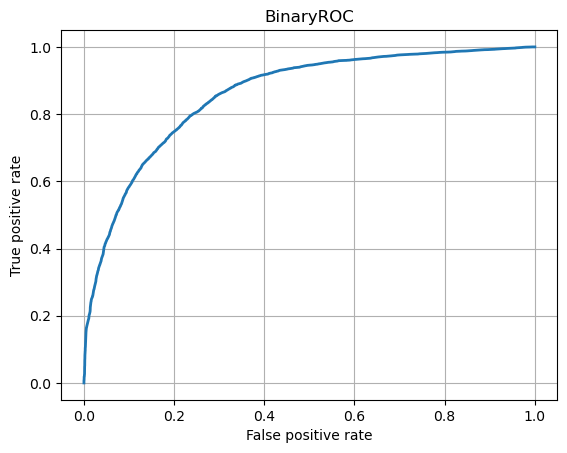

In [108]:
init_mlp_model.roc.plot()
plt.show()

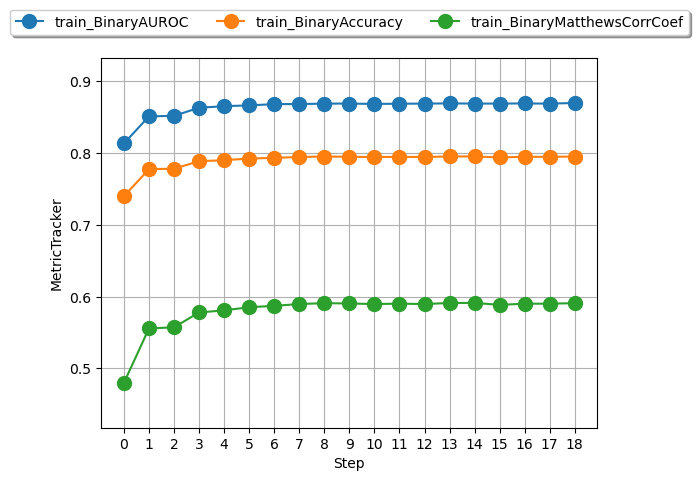

In [111]:
import matplotlib.pyplot as plt
init_mlp_model.train_tracker.plot()
plt.show()

In [65]:
init_mlp_model.valid_metrics.compute()


{'valid_BinaryAUROC': tensor(0.8506),
 'valid_BinaryAccuracy': tensor(0.7663),
 'valid_BinaryMatthewsCorrCoef': tensor(0.5332)}